In [11]:
from google.colab import userdata
tok = userdata.get("GH_TOKEN")
!git clone https://{tok}@github.com/mennanasa12-cloud/paradox_perception.git /content/repo

Cloning into '/content/repo'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 33 (delta 7), reused 33 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), done.
Resolving deltas: 100% (7/7), done.


In [1]:
!pip -q install huggingface_hub

from huggingface_hub import HfApi
api = HfApi()
files = api.list_repo_files("JeremyLuo/LuSNAR", repo_type="dataset")
print(len(files), "files")

# Show the top-level folders and a few example paths
tops = sorted({f.split("/")[0] for f in files})
print(tops)
for f in files[:30]:
    print(f)

11 files
['.gitattributes', 'Moon_1.zip', 'Moon_2.zip', 'Moon_3.zip', 'Moon_4.zip', 'Moon_5.zip', 'Moon_6.zip', 'Moon_7.zip', 'Moon_8.zip', 'Moon_9.zip', 'README.md']
.gitattributes
Moon_1.zip
Moon_2.zip
Moon_3.zip
Moon_4.zip
Moon_5.zip
Moon_6.zip
Moon_7.zip
Moon_8.zip
Moon_9.zip
README.md


In [2]:
from huggingface_hub import snapshot_download
snapshot_download(
    repo_id="JeremyLuo/LuSNAR",
    repo_type="dataset",
    allow_patterns=["*image1/RGB/*", "*image1/Label/*"],  # to be confirmed
    local_dir="/content/lusnar",
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 0 files: 0it [00:00, ?it/s]

'/content/lusnar'

In [6]:
from huggingface_hub import hf_hub_download
import zipfile, os

os.makedirs("/content/subset", exist_ok=True)
KEEP = ("/image0/color/", "/image0/label/")

for k in range(1, 10):
    name = f"Moon_{k}.zip"
    p = hf_hub_download("JeremyLuo/LuSNAR", name, repo_type="dataset",
                        local_dir="/content/zips")
    with zipfile.ZipFile(p) as z:
        members = [m for m in z.namelist() if any(s in m for s in KEEP) and not m.endswith("/")]
        z.extractall("/content/subset", members=members)
    os.remove(p)                      # free disk before the next zip
    print(name, "->", len(members), "files extracted")

!du -sh /content/subset
!ls /content/subset
!ls /content/subset/Moon_1/image0/color | head -3
!ls /content/subset/Moon_1/image0/label | head -3

Moon_1.zip -> 2188 files extracted


Moon_2.zip: reconstructing file:   0%|          |  0.00B / 6.36GB            

Moon_2.zip: downloading bytes:           |  0.00B            

Moon_2.zip -> 3196 files extracted


Moon_3.zip: reconstructing file:   0%|          |  0.00B / 4.86GB            

...

Moon_8.zip: downloading bytes:           |  0.00B            

Moon_8.zip -> 2704 files extracted


Moon_9.zip: reconstructing file:   0%|          |  0.00B / 8.69GB            

Moon_9.zip: downloading bytes:           |  0.00B            

Moon_9.zip -> 4176 files extracted
22G	/content/subset
Moon_1	Moon_2	Moon_3	Moon_4	Moon_5	Moon_6	Moon_7	Moon_8	Moon_9
1693274724086398208.png
1693274724419036672.png
1693274724752036608.png
1693274724086398208.png
1693274724419036672.png
1693274724752036608.png


In [8]:
import glob, numpy as np
from PIL import Image

for k in range(1, 10):
    files = sorted(glob.glob(f"/content/subset/Moon_{k}/image0/label/*.png"))
    f = files[len(files)//2]
    im = Image.open(f)
    a = np.array(im.convert("RGB"))
    cols, cnt = np.unique(a.reshape(-1, 3), axis=0, return_counts=True)
    tot = a.shape[0] * a.shape[1]
    top = sorted(zip(cnt, cols), key=lambda x: -x[0])[:8]
    print(f"Moon_{k} | {len(files)} frames | mode={im.mode} | size={im.size}")
    print("   ", [("#%02X%02X%02X" % tuple(c), f"{n/tot*100:.1f}%") for n, c in top])

Moon_1 | 1094 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '67.3%'), ('#22C9F8', '21.5%'), ('#AD451F', '9.4%'), ('#E8FA50', '1.8%')]
Moon_2 | 1597 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '68.9%'), ('#22C9F8', '25.1%'), ('#AD451F', '3.3%'), ('#E8FA50', '2.8%')]
Moon_3 | 1230 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '69.2%'), ('#22C9F8', '25.8%'), ('#AD451F', '2.8%'), ('#7800C8', '1.8%'), ('#E8FA50', '0.5%')]
Moon_4 | 1320 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '67.3%'), ('#22C9F8', '25.7%'), ('#7800C8', '5.8%'), ('#E8FA50', '1.3%')]
Moon_5 | 1599 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '73.4%'), ('#22C9F8', '23.7%'), ('#7800C8', '1.5%'), ('#E8FA50', '1.4%')]
Moon_6 | 1102 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '69.0%'), ('#22C9F8', '20.3%'), ('#AD451F', '5.6%'), ('#E8FA50', '4.4%'), ('#7800C8', '0.7%')]
Moon_7 | 1626 frames | mode=P | size=(1024, 1024)
    [('#BB469C', '68.6%'), ('#22C9F8', '25.2%'), ('#AD451F', '

In [9]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/data
!cp /content/drive/MyDrive/paradox/lusnar_processed.zip /content/data/
!cd /content/data && unzip -q lusnar_processed.zip

Mounted at /content/drive
cp: cannot stat '/content/drive/MyDrive/paradox/lusnar_processed.zip': No such file or directory
unzip:  cannot find or open lusnar_processed.zip, lusnar_processed.zip.zip or lusnar_processed.zip.ZIP.


train 1916 images, 1916 masks | {0: '68.87%', 1: '1.23%', 2: '2.21%', 3: '3.06%', 4: '24.63%'}
val 271 images, 271 masks | {0: '68.99%', 1: '2.05%', 2: '1.48%', 3: '3.51%', 4: '23.98%'}
test 418 images, 418 masks | {0: '68.03%', 1: '1.34%', 2: '4.43%', 3: '3.56%', 4: '22.64%'}
(class 255 = unknown color; it should be 0% or absent)
class weights: {0: np.float64(0.244), 1: np.float64(1.829), 2: np.float64(1.361), 3: np.float64(1.158), 4: np.float64(0.408)}
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
zip size GB: 1.12
saved to Drive: lusnar_processed.zip + class_stats.json


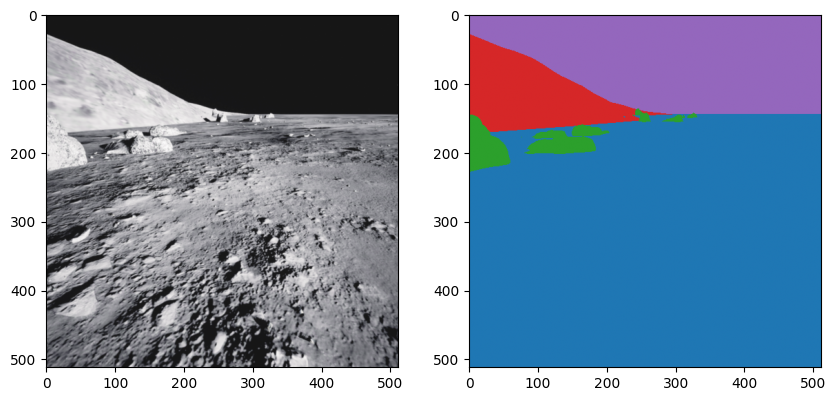

In [13]:
import glob, os, shutil, json, numpy as np
from PIL import Image
from collections import defaultdict

SRC, OUT, STEP, SIZE = "/content/subset", "/content/processed", 5, 512
SPLITS = {"train": range(1, 8), "val": [8], "test": [9]}

# same colors as segmentation_colors in configs/classes.yaml
HEX = {0: "#BB469C", 1: "#7800C8", 2: "#E8FA50", 3: "#AD451F", 4: "#22C9F8"}
RGB = {k: tuple(int(v[i:i+2], 16) for i in (1, 3, 5)) for k, v in HEX.items()}

def to_mask(label_path):
    a = np.array(Image.open(label_path).convert("RGB"))
    m = np.full(a.shape[:2], 255, np.uint8)          # 255 = unknown color (ignored in loss)
    for cid, rgb in RGB.items():
        m[(a == rgb).all(-1)] = cid
    return m

shutil.rmtree(OUT, ignore_errors=True)
stats = {s: defaultdict(int) for s in SPLITS}

for split, scenes in SPLITS.items():
    os.makedirs(f"{OUT}/{split}/images"); os.makedirs(f"{OUT}/{split}/masks")
    for k in scenes:
        col = {os.path.basename(p) for p in glob.glob(f"{SRC}/Moon_{k}/image0/color/*.png")}
        lab = {os.path.basename(p) for p in glob.glob(f"{SRC}/Moon_{k}/image0/label/*.png")}
        names = sorted(col & lab)[::STEP]
        for n in names:
            m = to_mask(f"{SRC}/Moon_{k}/image0/label/{n}")
            m = np.array(Image.fromarray(m).resize((SIZE, SIZE), Image.NEAREST))
            for cid, c in zip(*np.unique(m, return_counts=True)):
                stats[split][int(cid)] += int(c)
            Image.open(f"{SRC}/Moon_{k}/image0/color/{n}").convert("RGB") \
                 .resize((SIZE, SIZE), Image.BILINEAR).save(f"{OUT}/{split}/images/Moon_{k}_{n}")
            Image.fromarray(m).save(f"{OUT}/{split}/masks/Moon_{k}_{n}")
    n_img = len(os.listdir(f"{OUT}/{split}/images"))
    n_msk = len(os.listdir(f"{OUT}/{split}/masks"))
    tot = sum(stats[split].values())
    print(split, n_img, "images,", n_msk, "masks |",
          {c: f"{v/tot*100:.2f}%" for c, v in sorted(stats[split].items())})
print("(class 255 = unknown color; it should be 0% or absent)")

# ---- class weights from the TRAIN split (inverse sqrt frequency, mean = 1) ----
tr = {c: stats["train"].get(c, 0) for c in range(5)}
tot_tr = sum(tr.values())
inv = {c: (1 / np.sqrt(v / tot_tr) if v > 0 else 0.0) for c, v in tr.items()}
s = sum(inv.values())
weights = {c: round(5 * x / s, 3) for c, x in inv.items()}
print("class weights:", weights)

os.makedirs("/content/drive/MyDrive/paradox", exist_ok=True) if os.path.isdir("/content/drive") else None

# ---- zip locally, then copy to Drive in one go ----
shutil.make_archive("/content/lusnar_processed", "zip", OUT)
from google.colab import drive
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/paradox", exist_ok=True)
shutil.copy("/content/lusnar_processed.zip", "/content/drive/MyDrive/paradox/")
json.dump({"class_weights": weights,
           "pixel_counts": {sp: dict(d) for sp, d in stats.items()}},
          open("/content/drive/MyDrive/paradox/class_stats.json", "w"), indent=2)
print("zip size GB:", round(os.path.getsize("/content/lusnar_processed.zip") / 1e9, 2))
print("saved to Drive: lusnar_processed.zip + class_stats.json")

# ---- quick visual check: image next to its mask ----
import matplotlib.pyplot as plt
x = sorted(glob.glob(f"{OUT}/train/images/*.png"))[100]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(Image.open(x))
ax[1].imshow(np.array(Image.open(x.replace("/images/", "/masks/"))), cmap="tab10", vmin=0, vmax=9)
plt.show()

In [15]:
!ls -la /content/repo/src/perception/
!ls -la /content/repo/src/perception/dataset/ 2>&1

total 16
drwxr-xr-x 4 root root 4096 Oct  9 19:41 .
drwxr-xr-x 3 root root 4096 Oct  9 18:53 ..
-rw-r--r-- 1 root root    0 Oct  9 18:53 __init__.py
drwxr-xr-x 2 root root 4096 Oct  9 19:41 __pycache__
drwxr-xr-x 2 root root 4096 Oct  9 18:53 utils
ls: cannot access '/content/repo/src/perception/dataset/': No such file or directory


In [17]:
!mkdir -p /content/repo/src/perception/dataset
!touch /content/repo/src/perception/dataset/__init__.py
!pip -q install albumentations

In [18]:
%%writefile /content/repo/src/perception/dataset/lusnar_seg.py
from pathlib import Path
import numpy as np
from PIL import Image
import albumentations as A
from albumentations.pytorch import ToTensorV2

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def get_transforms(train: bool):
    norm = [A.Normalize(mean=MEAN, std=STD), ToTensorV2()]
    if not train:
        return A.Compose(norm)
    # horizontal flip only (sky is always on top); no hue shifts (the Moon is nearly colorless)
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=0.7),
        A.RandomGamma(gamma_limit=(70, 130), p=0.3),
        A.GaussianBlur(blur_limit=(3, 5), p=0.2),
        A.GaussNoise(p=0.2),
    ] + norm)

class LuSNARSeg:
    """Reads <root>/<split>/images/*.png and masks/*.png (class IDs 0-4, 255=ignore)."""
    def __init__(self, root, split, train=None):
        self.img_dir = Path(root) / split / "images"
        self.mask_dir = Path(root) / split / "masks"
        self.names = sorted(p.name for p in self.img_dir.glob("*.png"))
        self.tf = get_transforms(split == "train" if train is None else train)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, i):
        n = self.names[i]
        img = np.array(Image.open(self.img_dir / n).convert("RGB"))
        mask = np.array(Image.open(self.mask_dir / n))
        out = self.tf(image=img, mask=mask)
        return out["image"], out["mask"].long()

Writing /content/repo/src/perception/dataset/lusnar_seg.py


In [19]:
!ls -la /content/repo/src/perception/dataset/

total 12
drwxr-xr-x 2 root root 4096 Oct  9 19:43 .
drwxr-xr-x 5 root root 4096 Oct  9 19:42 ..
-rw-r--r-- 1 root root    0 Oct  9 19:42 __init__.py
-rw-r--r-- 1 root root 1462 Oct  9 19:43 lusnar_seg.py


In [20]:
import importlib, sys
importlib.invalidate_caches()
for m in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[m]
import sys; sys.path.insert(0, "/content/repo")
from src.perception.dataset.lusnar_seg import LuSNARSeg

for s in ["train", "val", "test"]:
    ds = LuSNARSeg("/content/processed", s)
    x, y = ds[0]
    print(s, len(ds), x.shape, y.shape, y.unique().tolist())

!cd /content/repo && git config user.name "Menna Tarek" && git config user.email "menna.space.claude@gmail.com" \
 && git add src/perception/dataset && git commit -m "feat: LuSNAR segmentation dataset and augmentations" && git push

train 1916 torch.Size([3, 512, 512]) torch.Size([512, 512]) [0, 2, 3, 4]
val 271 torch.Size([3, 512, 512]) torch.Size([512, 512]) [0, 1, 2, 3, 4]
test 418 torch.Size([3, 512, 512]) torch.Size([512, 512]) [0, 1, 2, 3, 4]
[master b08c34c] feat: LuSNAR segmentation dataset and augmentations
 2 files changed, 38 insertions(+)
 create mode 100644 src/perception/dataset/__init__.py
 create mode 100644 src/perception/dataset/lusnar_seg.py
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (6/6), 1.21 KiB | 1.21 MiB/s, done.
Total 6 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/mennanasa12-cloud/paradox_perception.git
   c373c29..b08c34c  master -> master
